# Notebook Dedicated to Analyze the Response in Charge of the PMTs and its Relation with Directionality

In [1]:
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sn

from scipy.stats import gaussian_kde
from scipy.optimize import brentq

import glob

# Load Data

In [39]:
fdir = '/home/joankl/data/solars/mc/2p2PPO/electrons/results_npz/resume/PMT_charge/*.npz'
flist = glob.glob(fdir)
print(flist)

data_e_5MeV, data_e_3MeV, data_e_2_5MeV = np.load(flist[0]), np.load(flist[1]), np.load(flist[2])

q_tot_scint_only_5MeV = data_e_5MeV['q_tot_scint_only']
q_tot_cher_scint_5MeV = data_e_5MeV['q_tot_cher_scint']
q_tot_scint_only_3MeV = data_e_3MeV['q_tot_scint_only']
q_tot_cher_scint_3MeV = data_e_3MeV['q_tot_cher_scint']
q_tot_scint_only_2_5MeV = data_e_2_5MeV['q_tot_scint_only']
q_tot_cher_scint_2_5MeV = data_e_2_5MeV['q_tot_cher_scint']

q_per_pmt_scint_only_5MeV = data_e_5MeV['q_per_pmt_scint_only']
q_per_pmt_cher_scint_5MeV = data_e_5MeV['q_per_pmt_cher_scint']
q_per_pmt_scint_only_3MeV = data_e_3MeV['q_per_pmt_scint_only']
q_per_pmt_cher_scint_3MeV = data_e_3MeV['q_per_pmt_cher_scint']
q_per_pmt_scint_only_2_5MeV = data_e_2_5MeV['q_per_pmt_scint_only']
q_per_pmt_cher_scint_2_5MeV = data_e_2_5MeV['q_per_pmt_cher_scint']

norm_q_scint_only_5MeV = data_e_5MeV['norm_q_scint_only']
norm_q_cher_scint_5MeV = data_e_5MeV['norm_q_cher_scint']
norm_q_scint_only_3MeV = data_e_3MeV['norm_q_scint_only']
norm_q_cher_scint_3MeV = data_e_3MeV['norm_q_cher_scint']
norm_q_scint_only_2_5MeV = data_e_2_5MeV['norm_q_scint_only']
norm_q_cher_scint_2_5MeV = data_e_2_5MeV['norm_q_cher_scint']

nhits_scint_only_5MeV = data_e_5MeV['nhits_scint_only']
nhits_cher_scint_5MeV = data_e_5MeV['nhits_cher_scint']

nhits_scint_only_3MeV = data_e_3MeV['nhits_scint_only']
nhits_cher_scint_3MeV = data_e_3MeV['nhits_cher_scint']

nhits_scint_only_2_5MeV = data_e_2_5MeV['nhits_scint_only']
nhits_cher_scint_2_5MeV = data_e_2_5MeV['nhits_cher_scint']

# Normalize total charges
norm_q_tot_scint_only_5MeV = q_tot_scint_only_5MeV[q_tot_scint_only_5MeV > 0] / nhits_scint_only_5MeV[q_tot_scint_only_5MeV > 0]
norm_q_tot_norm_cher_scint_5MeV = q_tot_cher_scint_5MeV[q_tot_cher_scint_5MeV > 0] / nhits_cher_scint_5MeV[q_tot_cher_scint_5MeV > 0]

norm_q_tot_scint_only_3MeV = q_tot_scint_only_3MeV[q_tot_scint_only_3MeV > 0] / nhits_scint_only_3MeV[q_tot_scint_only_3MeV > 0]
norm_q_tot_norm_cher_scint_3MeV = q_tot_cher_scint_3MeV[q_tot_cher_scint_3MeV > 0] / nhits_cher_scint_3MeV[q_tot_cher_scint_3MeV > 0]

norm_q_tot_scint_only_2_5MeV = q_tot_scint_only_2_5MeV[q_tot_scint_only_2_5MeV > 0] / nhits_scint_only_2_5MeV[q_tot_scint_only_2_5MeV > 0]
norm_q_tot_norm_cher_scint_2_5MeV = q_tot_cher_scint_2_5MeV[q_tot_cher_scint_2_5MeV > 0] / nhits_cher_scint_2_5MeV[q_tot_cher_scint_2_5MeV > 0]

['/home/joankl/data/solars/mc/2p2PPO/electrons/results_npz/resume/summary_e_5.0MeV.npz', '/home/joankl/data/solars/mc/2p2PPO/electrons/results_npz/resume/summary_e_3.0MeV.npz', '/home/joankl/data/solars/mc/2p2PPO/electrons/results_npz/resume/summary_e_2.5MeV.npz']


In [14]:
list(data_e_5MeV.keys())

['mcid',
 'evtid',
 'q_tot_scint_only',
 'q_tot_cher_scint',
 'q_per_pmt_scint_only',
 'q_per_pmt_cher_scint',
 'norm_q_scint_only',
 'norm_q_cher_scint',
 'nhits_scint_only',
 'nhits_cher_scint']

# Plots

In [85]:
# Lista de energias en la simulacion
energies = [5, 3, 2.5]

# Agrupar los datos para iterar limpiamente
scint_data = [norm_q_scint_only_5MeV, norm_q_scint_only_3MeV, norm_q_scint_only_2_5MeV]
cher_data = [norm_q_cher_scint_5MeV, norm_q_cher_scint_3MeV, norm_q_cher_scint_2_5MeV]

## Total Charge per Event

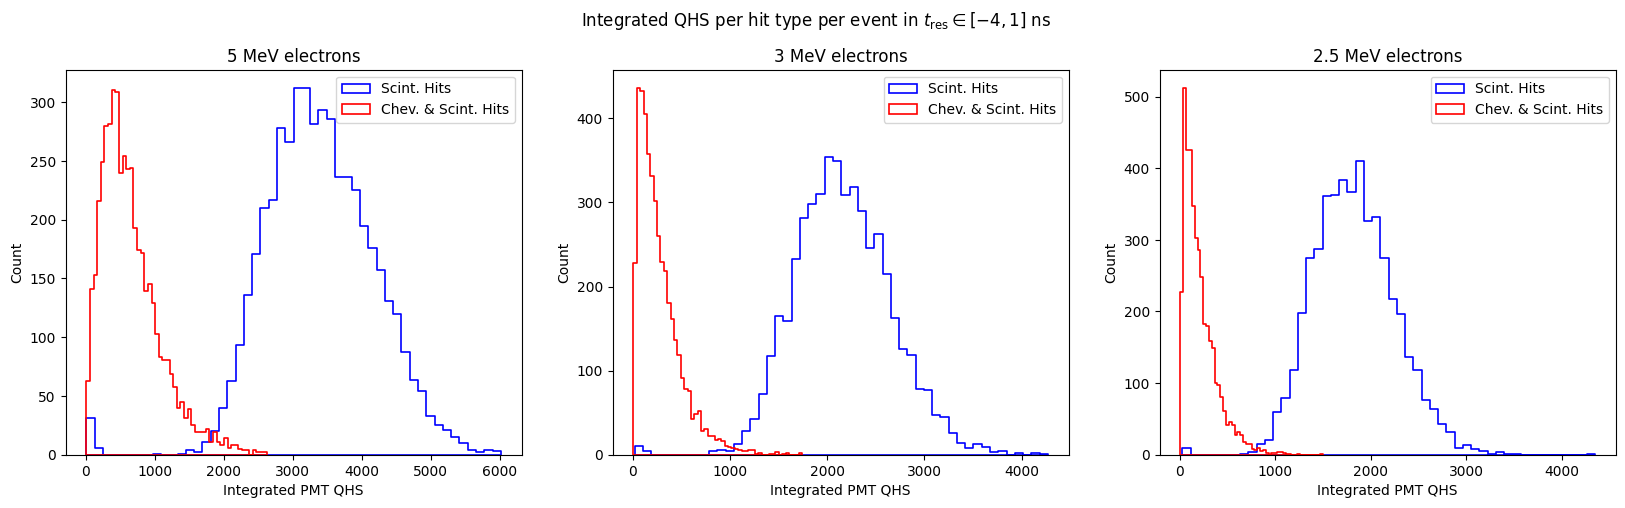

In [91]:
bins = 50

fig, axes = plt.subplots(1, 3, figsize = (20, 5))

sn.histplot(q_tot_scint_only_5MeV[q_tot_scint_only_5MeV > 0], bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Scint. Hits', color = 'blue', ax = axes[0])
sn.histplot(q_tot_cher_scint_5MeV[q_tot_cher_scint_5MeV > 0], bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Chev. & Scint. Hits', color = 'red', ax = axes[0])

sn.histplot(q_tot_scint_only_3MeV[q_tot_scint_only_3MeV > 0], bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Scint. Hits', color = 'blue', ax = axes[1])
sn.histplot(q_tot_cher_scint_3MeV[q_tot_cher_scint_3MeV > 0], bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Chev. & Scint. Hits', color = 'red',  ax = axes[1])

sn.histplot(q_tot_scint_only_2_5MeV[q_tot_scint_only_2_5MeV > 0], bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Scint. Hits', color = 'blue', ax = axes[2])
sn.histplot(q_tot_cher_scint_2_5MeV[q_tot_cher_scint_2_5MeV > 0], bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Chev. & Scint. Hits', color = 'red', ax = axes[2])

for i_dx, ax in enumerate(axes):
    ax.set_title(f'{energies[i_dx]} MeV electrons')
    ax.set_xlabel('Integrated PMT QHS')
    ax.legend(loc = 'upper right')
    
plt.suptitle(r'Integrated QHS per hit type per event in $t_\text{res} \in [-4,1]$ ns', y = 1.0)

plt.show()

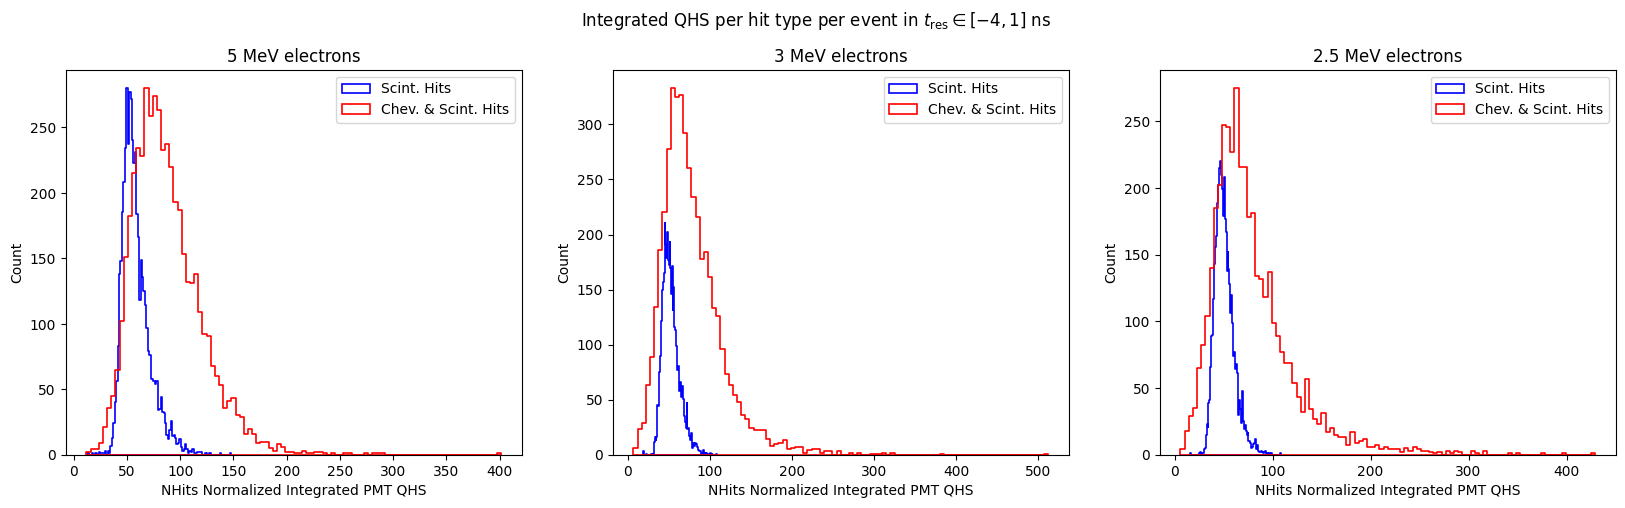

In [92]:
bins = 100

fig, axes = plt.subplots(1, 3, figsize = (20, 5))

sn.histplot(norm_q_tot_scint_only_5MeV, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Scint. Hits', color = 'blue', ax = axes[0])
sn.histplot(norm_q_tot_norm_cher_scint_5MeV, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Chev. & Scint. Hits', color = 'red', ax = axes[0])

sn.histplot(norm_q_tot_scint_only_3MeV, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Scint. Hits', color = 'blue', ax = axes[1])
sn.histplot(norm_q_tot_norm_cher_scint_3MeV, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Chev. & Scint. Hits', color = 'red', ax = axes[1])

sn.histplot(norm_q_tot_scint_only_2_5MeV, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Scint. Hits', color = 'blue', ax = axes[2])
sn.histplot(norm_q_tot_norm_cher_scint_2_5MeV, bins = bins, element = 'step', alpha = 0, lw = 1.2, label = 'Chev. & Scint. Hits', color = 'red', ax = axes[2])

for i_dx, ax in enumerate(axes):
    ax.set_title(f'{energies[i_dx]} MeV electrons')
    ax.set_xlabel('NHits Normalized Integrated PMT QHS')
    ax.legend(loc = 'upper right')
    
plt.suptitle(r'Integrated QHS per hit type per event in $t_\text{res} \in [-4,1]$ ns', y = 1.0)

plt.show()

## Total Charge per PMT per Event

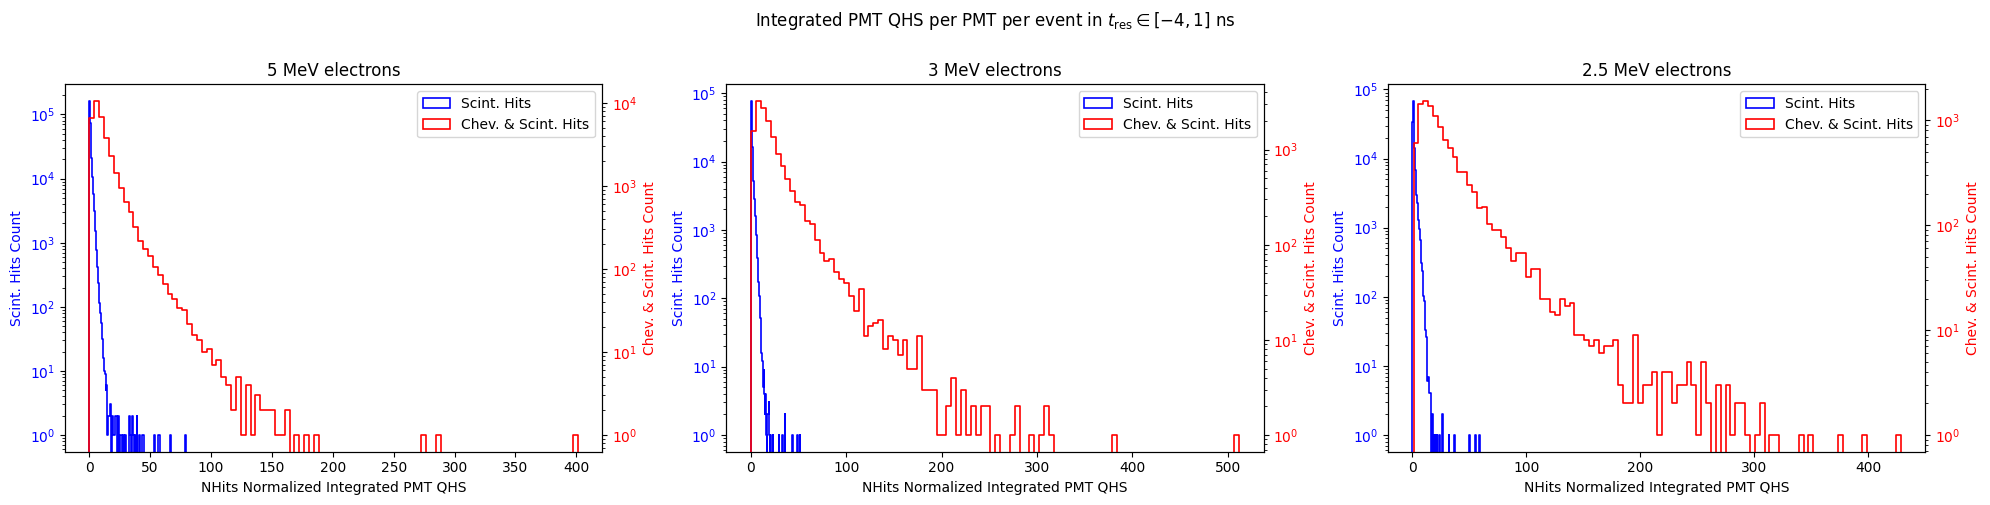

In [93]:
bins = 100

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for i, (ax1, sc_d, ch_d, e) in enumerate(zip(axes, scint_data, cher_data, energies)):
    # 1. Eje Izquierdo (Azul - Scint. Hits)
    sn.histplot(
        sc_d, bins=bins, element='step', alpha=0, lw=1.2, 
        label='Scint. Hits', color='blue', ax=ax1
    )
    ax1.set_yscale('log')
    ax1.set_ylabel('Scint. Hits Count', color='blue')
    ax1.tick_params(axis='y', labelcolor='blue')
    ax1.set_xlabel('NHits Normalized Integrated PMT QHS')
    ax1.set_title(f'{e} MeV electrons')

    # 2. Eje Secundario Derecho (Rojo - Chev. & Scint. Hits)
    ax2 = ax1.twinx()
    sn.histplot(
        ch_d, bins=bins, element='step', alpha=0, lw=1.2, 
        label='Chev. & Scint. Hits', color='red', ax=ax2
    )
    ax2.set_yscale('log')
    ax2.set_ylabel('Chev. & Scint. Hits Count', color='red')
    ax2.tick_params(axis='y', labelcolor='red')

    # Desactivar la cuadrícula del eje secundario para evitar solapamientos visuales
    ax2.grid(False)

    # 3. Combinar las leyendas de ambos ejes en una sola
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right')
    
    # Remover leyenda automática residual de ax2 si seaborn la genera
    if ax2.get_legend():
        ax2.get_legend().remove()

plt.suptitle(r'Integrated PMT QHS per PMT per event in $t_\text{res} \in [-4,1]$ ns', y=1.00)
plt.tight_layout()
plt.show()